# Imaging, resolution and aberrations

This notebook combines `pyoptics.imaging` (coherent imaging through a 4f system
with numerical aperture NA), `pyoptics.bases` (Fringe Zernike polynomials for
wavefront errors) and `pyoptics.propagators` (three-dimensional point spread
function). Topics: Zernike gallery, point spread function (PSF) with aberrations,
Strehl ratio and Maréchal approximation, Zernike fit, coherent and incoherent
imaging, the Rayleigh criterion and the focus in 3D. Notebook 16 looks at the
basis functions themselves in more depth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from pyoptics import imaging
from pyoptics import propagators as prop
from pyoptics.bases import FringeZernikes, fringe_to_n_m
from pyoptics.fft import FT, inv_FT
from pyoptics.masks import circular_mask
from pyoptics.utils import grid2d, freq_grid, wavenumber

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

## 1. Fringe Zernike polynomials

Zernike polynomials $Z_j(\rho, \varphi)$ are orthogonal on the unit disk and
describe the typical aberrations of rotationally symmetric systems. `FringeZernikes`
numbers them in the Fringe order (index starting at 1) and normalizes them to
$|Z_j(\rho = 1)| = 1$.

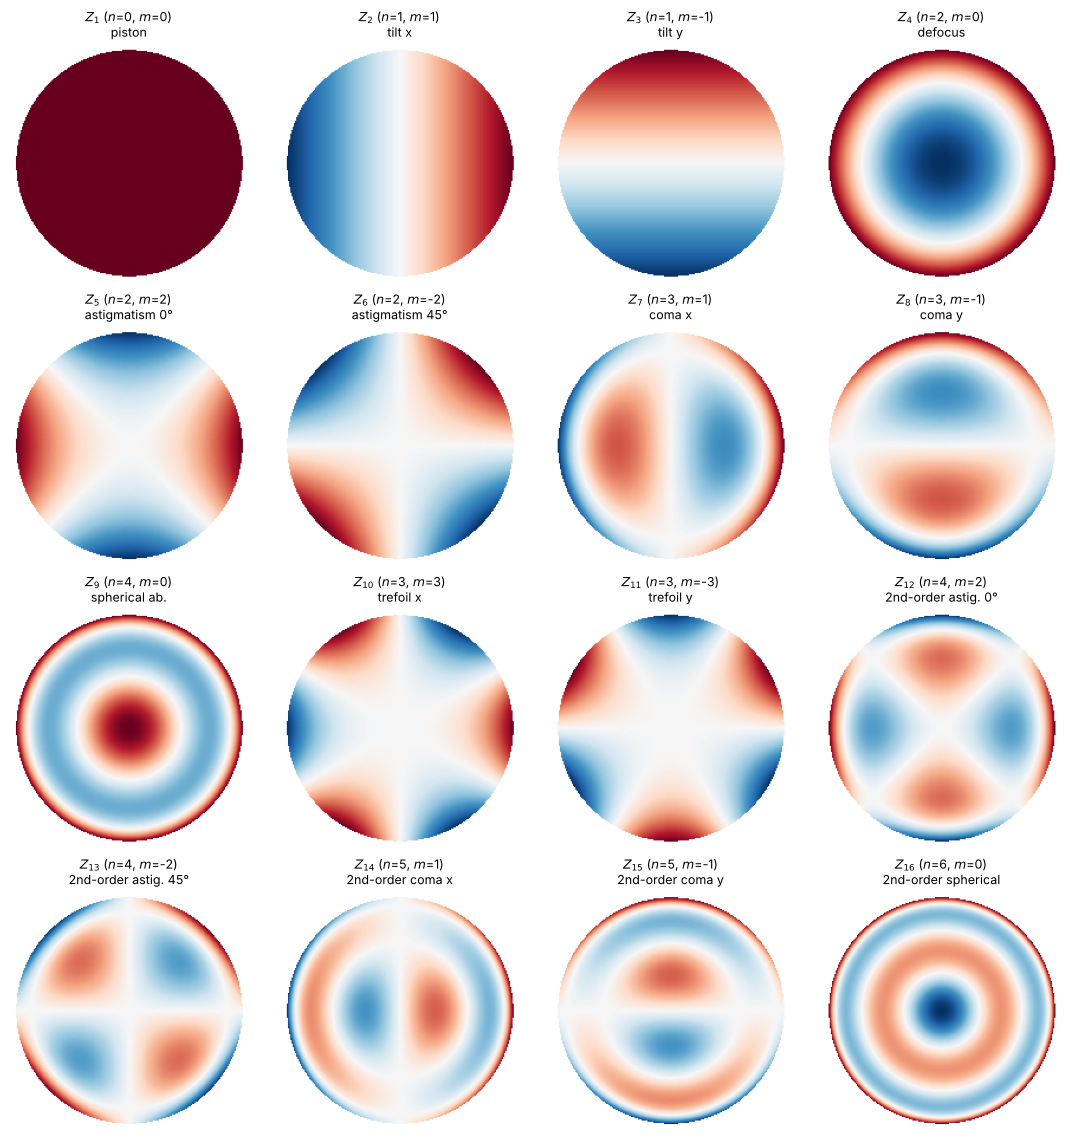

In [2]:
names = {1: "piston", 2: "tilt x", 3: "tilt y", 4: "defocus", 5: "astigmatism 0°",
         6: "astigmatism 45°", 7: "coma x", 8: "coma y", 9: "spherical ab.", 10: "trefoil x",
         11: "trefoil y", 12: "2nd-order astig. 0°", 13: "2nd-order astig. 45°", 14: "2nd-order coma x",
         15: "2nd-order coma y", 16: "2nd-order spherical"}
xp, yp, _, _ = grid2d(-1.05, 1.05, -1.05, 1.05, 201)
Zb = FringeZernikes(xp, yp)
mask_p = circular_mask(xp, yp, 1.0).astype(bool)

fig, axes = plt.subplots(4, 4, figsize=(11, 11.5))
for ax, j in zip(axes.flat, range(1, 17)):
    Zj = np.where(mask_p, Zb([j], [1.0]), np.nan)
    ax.imshow(Zj, cmap="RdBu_r", vmin=-1, vmax=1, extent=(xp[0], xp[-1], yp[0], yp[-1]))
    n, m = fringe_to_n_m(j)
    ax.set_title(f"$Z_{{{j}}}$ ($n$={n}, $m$={m})\n{names[j]}", fontsize=9)
    ax.axis("off")
fig.tight_layout()

## 2. Point spread function with aberrations

The pupil function is $P(\rho, \varphi) = \mathrm{circ}(\rho)\, e^{2\pi i W(\rho,\varphi)}$
with the wavefront error $W = \sum_j c_j Z_j$ in waves. The PSF is the squared
modulus of its Fourier transform. Zero padding by a factor of 8 around the pupil
samples the PSF finely enough; image coordinates are given in units of
$\lambda/\mathrm{NA}$.

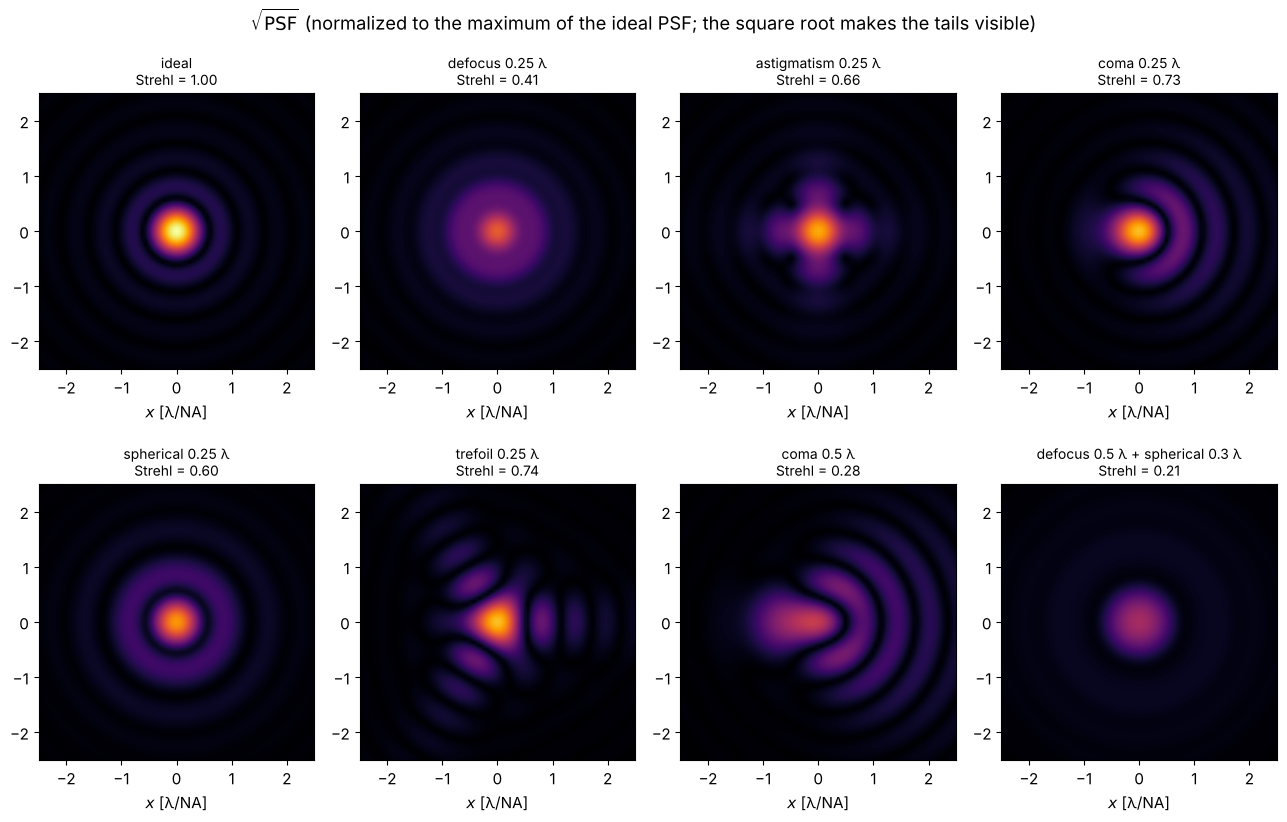

In [3]:
Lp, Np = 16.0, 1024           # pupil coordinates in units of the pupil radius
xq, yq, _, _ = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
Zq = FringeZernikes(xq, yq)
pupil = circular_mask(xq, yq, 1.0).astype(float)
u = np.fft.fftshift(np.fft.fftfreq(Np, xq[1] - xq[0]))  # image coordinate in lambda/NA

def psf(coeffs):
    """coeffs: dict {Fringe index: coefficient in waves}"""
    W = sum(c*Zq([j], [1.0]) for j, c in coeffs.items()) if coeffs else 0.0
    P = pupil*np.exp(2j*np.pi*W)
    return np.abs(FT(P))**2

I_perfect = psf({})
I0 = I_perfect.max()

cases = [({}, "ideal"), ({4: 0.25}, "defocus 0.25 λ"), ({5: 0.25}, "astigmatism 0.25 λ"),
         ({7: 0.25}, "coma 0.25 λ"), ({9: 0.25}, "spherical 0.25 λ"), ({10: 0.25}, "trefoil 0.25 λ"),
         ({7: 0.5}, "coma 0.5 λ"), ({4: 0.5, 9: 0.3}, "defocus 0.5 λ + spherical 0.3 λ")]
c = 2.5
sel = np.abs(u) <= c
fig, axes = plt.subplots(2, 4, figsize=(13, 8.4))
for ax, (coeffs, title) in zip(axes.flat, cases):
    I = psf(coeffs)
    ax.imshow(np.sqrt(I[np.ix_(sel, sel)]/I0), extent=(-c, c, -c, c), cmap="inferno", vmax=1.0, interpolation="bilinear")
    ax.set_title(f"{title}\nStrehl = {I.max()/I0:.2f}", fontsize=10)
    ax.set_xlabel("$x$ [λ/NA]")
fig.suptitle("$\\sqrt{\\mathrm{PSF}}$ (normalized to the maximum of the ideal PSF; the square root makes the tails visible)")
fig.tight_layout()

### Strehl ratio and the Maréchal approximation

The **Strehl ratio** is the peak intensity relative to the ideal PSF. For small
errors it depends only on the rms wavefront error $\sigma$, not on the type of
aberration:

$$S \approx \exp\big(-(2\pi\sigma)^2\big).$$

A system counts as "diffraction limited" for $S \geq 0.8$, i.e.
$\sigma \lesssim \lambda/14$ (Maréchal criterion). Note: tilt only shifts the PSF,
so we take the maximum of the PSF here rather than its value at the origin.

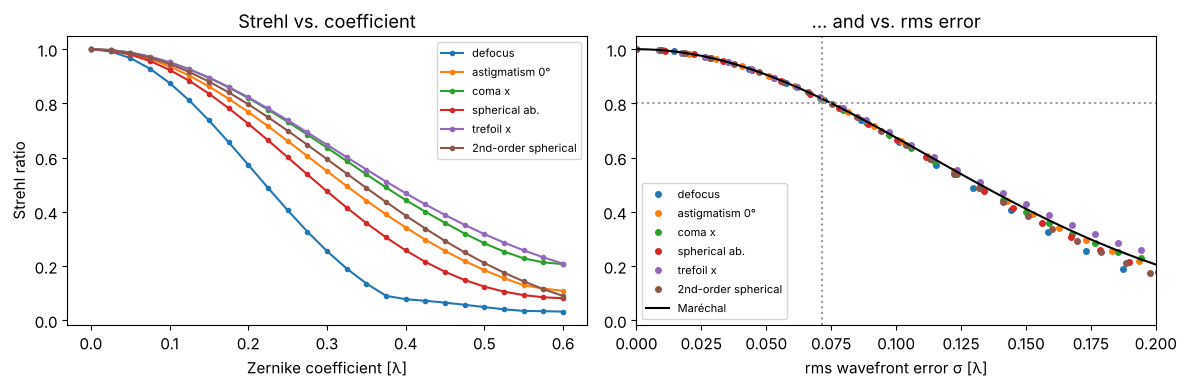

In [4]:
amps = np.linspace(0, 0.6, 25)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j in (4, 5, 7, 9, 10, 16):
    rms, strehl = [], []
    Zj = Zq([j], [1.0])
    for a in amps:
        rms.append(np.std(a*Zj[pupil > 0]))
        strehl.append(psf({j: a}).max()/I0)
    axes[0].plot(amps, strehl, "o-", ms=3, label=names[j])
    axes[1].plot(rms, strehl, "o", ms=4, label=names[j])
s = np.linspace(0, 0.2, 100)
axes[1].plot(s, np.exp(-(2*np.pi*s)**2), "k-", lw=1.5, label="Maréchal")
axes[1].axhline(0.8, color="0.6", ls=":"); axes[1].axvline(1/14, color="0.6", ls=":")
axes[0].set_xlabel("Zernike coefficient [λ]"); axes[0].set_ylabel("Strehl ratio")
axes[1].set_xlabel("rms wavefront error σ [λ]"); axes[1].set_xlim(0, 0.2)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
axes[0].set_title("Strehl vs. coefficient"); axes[1].set_title("... and vs. rms error")
fig.tight_layout()

## 3. Zernike fit of a measured wavefront

`coeffs_from_field()` decomposes a wavefront (here: synthetic, with noise) into
Zernike polynomials by least squares. The aberrations can be read off directly
from the coefficients.

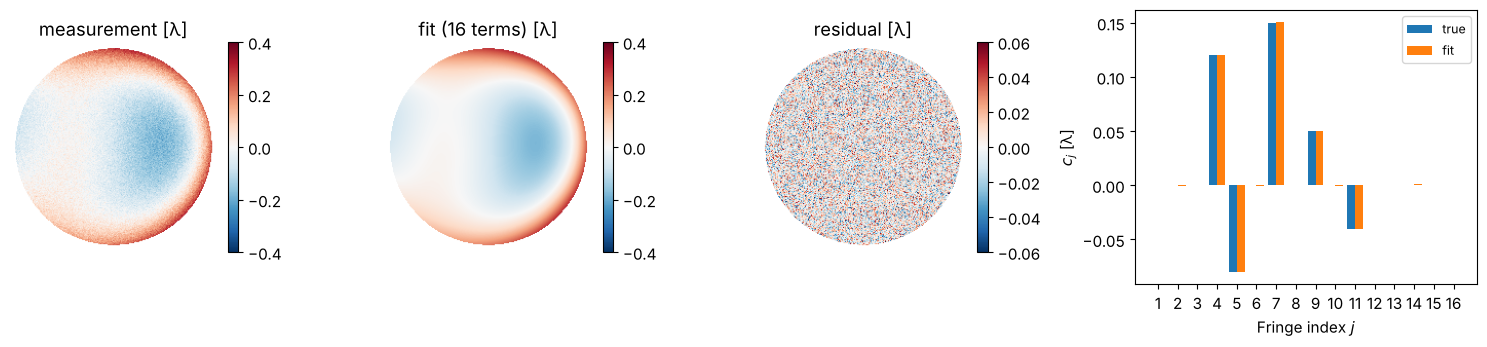

In [5]:
rng = np.random.default_rng(0)
true = {4: 0.12, 5: -0.08, 7: 0.15, 9: 0.05, 11: -0.04}
indices = list(range(1, 17))
W_true = sum(c*Zb([j], [1.0]) for j, c in true.items())
W_meas = W_true + 0.02*rng.standard_normal(W_true.shape)
W_meas_masked = np.where(mask_p, W_meas, 0.0)
coeffs_fit = Zb.coeffs_from_field(W_meas_masked, indices)
W_fit = Zb(indices, coeffs_fit)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
for ax, W, title in zip(axes, (W_meas, W_fit, W_meas - W_fit), ("measurement [λ]", "fit (16 terms) [λ]", "residual [λ]")):
    im = ax.imshow(np.where(mask_p, W, np.nan), cmap="RdBu_r", extent=(xp[0], xp[-1], yp[0], yp[-1]),
                   vmin=-0.4 if title != "residual [λ]" else -0.06, vmax=0.4 if title != "residual [λ]" else 0.06)
    fig.colorbar(im, ax=ax, fraction=0.046); ax.set_title(title); ax.axis("off")
axes[3].bar(np.array(indices) - 0.2, [true.get(j, 0.0) for j in indices], 0.4, label="true")
axes[3].bar(np.array(indices) + 0.2, np.real(coeffs_fit), 0.4, label="fit")
axes[3].set_xticks(indices); axes[3].set_xlabel("Fringe index $j$"); axes[3].set_ylabel("$c_j$ [λ]")
axes[3].legend(fontsize=9)
fig.tight_layout()

## 4. Coherent and incoherent imaging

`imaging.image()` images a (complex) object coherently: the spectrum is cut off at
$|k_\perp| > k\,\mathrm{NA}$. The coherent transfer function (CTF) is thus the
pupil itself, with the cut-off frequency $\mathrm{NA}/\lambda$.

With incoherent illumination (e.g. fluorescence), intensities add. The image is
the object intensity convolved with $|h|^2$, the intensity PSF (from
`imaging.get_psf()`). The optical transfer function (OTF) is the autocorrelation
of the pupil and reaches twice as far, up to $2\mathrm{NA}/\lambda$, but falls off
towards high frequencies.

A Siemens star shows both limits directly: the spokes blur towards the centre
where their period drops below the resolution limit.

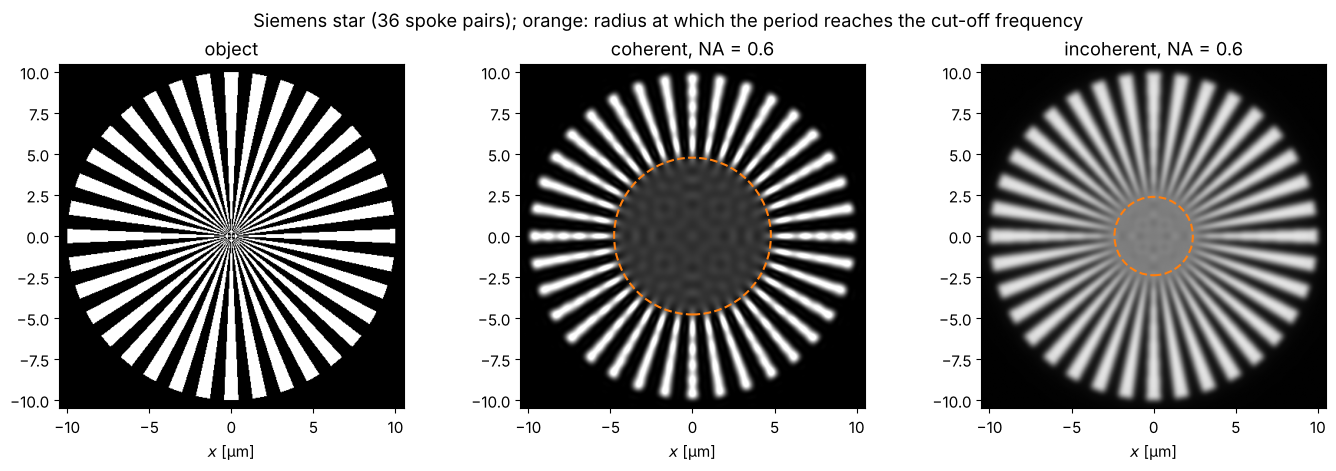

In [6]:
wl, NA = 0.5, 0.6
k = wavenumber(wl)
L, N = 24.0, 512
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
R, PHI = np.hypot(X, Y), np.arctan2(Y, X)
n_spokes = 36
star = ((np.cos(n_spokes*PHI) > 0) & (R < 10)).astype(float)

img_coh = np.abs(imaging.image(star, x, y, NA, k))**2
h = imaging.get_psf(x, y, NA, k)
H_inc = FT(np.abs(h)**2)
img_inc = np.real(inv_FT(FT(star)*H_inc/H_inc[N//2, N//2]))

r_coh = n_spokes*wl/(2*np.pi*NA)      # period 2 pi r / n_spokes = lambda/NA
r_inc = n_spokes*wl/(4*np.pi*NA)      # period = lambda/(2 NA)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for ax, I, title, r_lim in zip(axes, (star, img_coh, img_inc),
                               ("object", f"coherent, NA = {NA}", f"incoherent, NA = {NA}"),
                               (None, r_coh, r_inc)):
    ax.imshow(I, extent=(x[0], x[-1], y[0], y[-1]), cmap="gray", vmin=0, vmax=1.2 if I is img_coh else 1)
    if r_lim:
        ax.add_patch(plt.Circle((0, 0), r_lim, fill=False, color="C1", lw=1.5, ls="--"))
    ax.set_xlim(-10.5, 10.5); ax.set_ylim(-10.5, 10.5); ax.set_title(title); ax.set_xlabel("$x$ [µm]")
fig.suptitle("Siemens star (36 spoke pairs); orange: radius at which the period reaches the cut-off frequency")
fig.tight_layout()

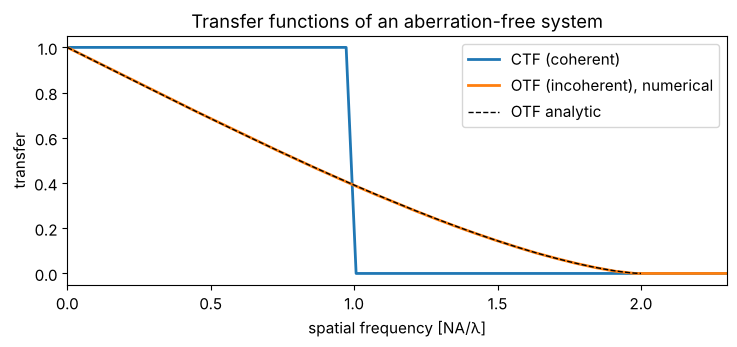

In [7]:
fx, fy = freq_grid(x, y, wavenumbers=False, normal_order=True)
CTF = (np.hypot(fx, fy) <= NA/wl).astype(float)
OTF = np.abs(H_inc)/np.abs(H_inc).max()
f_axis = fx[N//2]
nu = np.linspace(0, 1, 200)
otf_ana = 2/np.pi*(np.arccos(nu) - nu*np.sqrt(1 - nu**2))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(f_axis*wl/NA, CTF[N//2], lw=2, label="CTF (coherent)")
ax.plot(f_axis*wl/NA, OTF[N//2], lw=2, label="OTF (incoherent), numerical")
ax.plot(2*nu, otf_ana, "k--", lw=1, label="OTF analytic")
ax.set_xlim(0, 2.3); ax.set_xlabel("spatial frequency [NA/λ]"); ax.set_ylabel("transfer")
ax.legend(); ax.set_title("Transfer functions of an aberration-free system")
fig.tight_layout()

## 5. Two points: the Rayleigh criterion

Two incoherent point sources at a distance $0.61\,\lambda/\mathrm{NA}$ (maximum of
one PSF on the first zero of the other) are just resolved, with a dip to about
73 %. With **coherent** illumination the relative phase decides: points in phase
merge, points in antiphase are clearly separated by a dark line (the principle of
phase-shift masks in lithography).

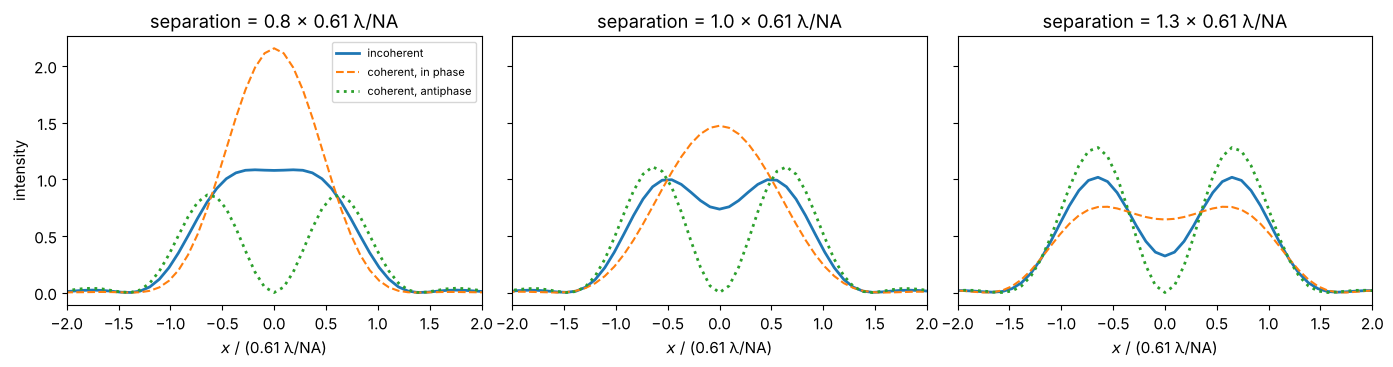

In [8]:
d_R = 0.61*wl/NA
KX, KY = freq_grid(x, y, wavenumbers=True, normal_order=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, sep in zip(axes, (0.8*d_R, d_R, 1.3*d_R)):
    shift = lambda f, dx: inv_FT(FT(f)*np.exp(-1j*KX*dx))  # shift by dx via the Fourier shift theorem
    h1, h2 = shift(h, -sep/2), shift(h, +sep/2)
    norm = np.abs(h).max()**2
    ax.plot(x/d_R, (np.abs(h1)**2 + np.abs(h2)**2)[N//2]/norm, lw=2, label="incoherent")
    ax.plot(x/d_R, np.abs(h1 + h2)[N//2]**2/norm, "--", label="coherent, in phase")
    ax.plot(x/d_R, np.abs(h1 - h2)[N//2]**2/norm, ":", lw=2, label="coherent, antiphase")
    ax.set_xlim(-2, 2); ax.set_xlabel("$x$ / (0.61 λ/NA)")
    ax.set_title(f"separation = {sep/d_R:.1f} × 0.61 λ/NA")
axes[0].set_ylabel("intensity"); axes[0].legend(fontsize=8)
fig.tight_layout()

## 6. The focus in three dimensions

The field in the focal plane is the (amplitude) PSF $h$. Propagating it forwards
and backwards with the exact Rayleigh-Sommerfeld propagator gives the
three-dimensional PSF. For small NA, on the axis,

$$I(0, 0, z) = I_0\,\mathrm{sinc}^2\!\left(\frac{\mathrm{NA}^2 z}{2\lambda}\right),
  \qquad \mathrm{sinc}(x) = \frac{\sin \pi x}{\pi x},$$

with the first zero at $z = 2\lambda/\mathrm{NA}^2$. At large NA, the focus is
shorter than the paraxial formula predicts, because the marginal rays arrive more
steeply.

**Careful with backward propagation:** for $z < 0$, evanescent components are
*amplified* by $e^{+|k_z||z|}$. Even rounding errors of $10^{-16}$ in this frequency
range then grow without bound. Time reversal helps:
$U(-z) = \overline{\mathcal{P}_z\big[\overline{U}\big]}$. For propagating waves this
is exactly the backward propagation, while evanescent waves are damped instead of
amplified.

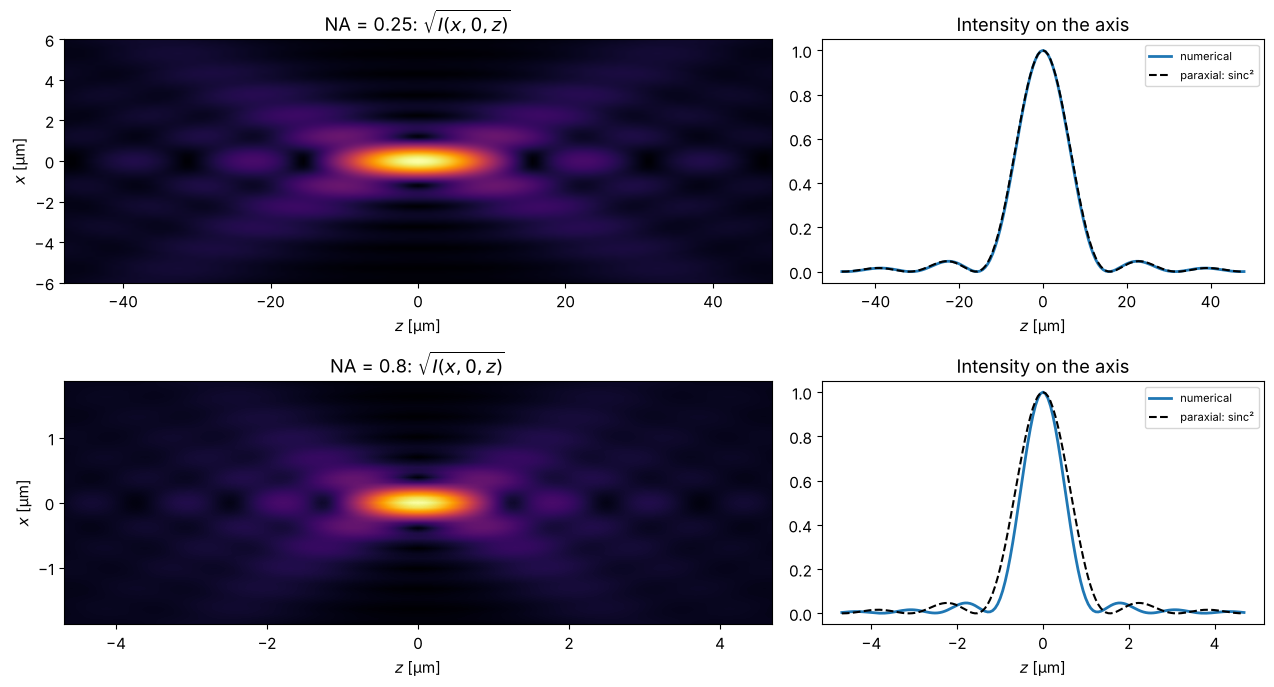

In [9]:
L3, N3 = 40.0, 512  # window large enough for the defocused cone of light
x3, y3, _, _ = grid2d(-L3/2, L3/2, -L3/2, L3/2, N3)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.6, 1]})
for row, NA3 in enumerate((0.25, 0.8)):
    h3 = imaging.get_psf(x3, y3, NA3, k)
    z_max = 3*2*wl/NA3**2
    z3 = np.linspace(-z_max, z_max, 161)
    def propagate(U, z):
        if z >= 0:
            return prop.rayleigh_sommerfeld_I_TF(U, x3, y3, z, wl)[0]
        return np.conj(prop.rayleigh_sommerfeld_I_TF(np.conj(U), x3, y3, -z, wl)[0])  # time reversal
    stack = np.array([propagate(h3, z)[N3//2] for z in z3])
    I3 = np.abs(stack)**2
    I3 /= I3.max()
    axes[row, 0].imshow(I3.T**0.5, extent=(z3[0], z3[-1], x3[0], x3[-1]), aspect="auto", cmap="inferno",
                        interpolation="bilinear")
    axes[row, 0].set_ylim(-3*wl/NA3, 3*wl/NA3)
    axes[row, 0].set_xlabel("$z$ [µm]"); axes[row, 0].set_ylabel("$x$ [µm]")
    axes[row, 0].set_title(f"NA = {NA3}: $\\sqrt{{I(x, 0, z)}}$")
    axes[row, 1].plot(z3, I3[:, N3//2], lw=2, label="numerical")
    axes[row, 1].plot(z3, np.sinc(NA3**2*z3/(2*wl))**2, "k--", label="paraxial: sinc²")
    axes[row, 1].set_xlabel("$z$ [µm]"); axes[row, 1].set_title("Intensity on the axis"); axes[row, 1].legend(fontsize=8)
fig.tight_layout()